# E-commerce Sales & Profitability Intelligence — Exploratory Data Analysis

> **The data in this project is SYNTHETIC.** It was generated by `src/generate_synthetic_data.py` (seed 42) to look like a
> retail sales extract. It does not describe a real company. Some relationships (for example *discounts reduce profit*) are
> partly built into the simulator, so the value of this notebook is the **method**. With a real dataset the numbers will differ
> and every causal statement would need more evidence.

**Business questions:** which products, regions and customer groups drive revenue and profit, where money is being lost, and how discounts relate to profit.

**Sections:** 1 Overview & quality · 2 Descriptive statistics · 3 Distributions · 4 Trends & seasonality · 5 Category & sub-category ·
6 Geography · 7 Product profitability · 8 Discounts · 9 Customer segments · 10 Outliers · 11 Reconciliation with SQL

**Definitions used throughout:** revenue = sum of `sales` (after discount, net of returns) · profit = sum of `profit` · orders = distinct `order_id` ·
profit margin = total profit ÷ total sales (never the average of line margins).

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
from matplotlib.patches import Patch
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.labelsize": 10})
BLUE, TEAL, RED, GREY = "#2E6F9E", "#2A9D8F", "#D1495B", "#8D99AE"
usd_k = mtick.FuncFormatter(lambda x, _: f"${x/1e3:,.0f}K")
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
def save(name): plt.savefig(FIG / name, dpi=130, bbox_inches="tight")

df = pd.read_csv("../data/processed/superstore_clean.csv", parse_dates=["order_date", "ship_date"], dtype={"postal_code": str})
sales_lines = df[df.is_return == 0]          # the 10 return lines are excluded from price / discount analysis
print(f"{len(df):,} rows x {df.shape[1]} columns | {df.order_date.min():%d %b %Y} to {df.order_date.max():%d %b %Y}")

8,679 rows x 28 columns | 01 Jan 2022 to 28 Dec 2025

## 1. Data overview and quality checks
The cleaning step (`src/data_cleaning.py`) already removed duplicates, standardised text and dates and quarantined invalid rows. Here we confirm the result before analysing.

In [2]:
len_df, n_orders, n_cust, n_prod = len(df), df.order_id.nunique(), df.customer_id.nunique(), df.product_id.nunique()
print(f"Orders: {n_orders:,} | Customers: {n_cust:,} | Products: {n_prod:,} | Cities: {df.city.nunique()}")
print("\nData types:"); print(df.dtypes.astype(str).to_string())
miss = df.isna().sum(); miss = miss[miss > 0]
print("\nColumns with missing values:"); print(miss.to_string())
n_ship_missing = int(df.ship_date.isna().sum())
print("\nFlag columns kept on purpose (rows flagged):"); print(df[["is_return", "is_price_outlier", "ship_date_invalid"]].sum().to_string())

Orders: 3,895 | Customers: 754 | Products: 174 | Cities: 27

Data types:
row_id                        int64
order_id                        str
order_date           datetime64[us]
ship_date            datetime64[us]
ship_days                   float64
ship_mode                       str
customer_id                     str
customer_name                   str
segment                         str
country                         str
state                           str
city                            str
postal_code                     str
region                          str
product_id                      str
product_name                    str
category                        str
sub_category                    str
sales                       float64
quantity                      int64
discount                    float64
profit                      float64
profit_margin               float64
year                          int64
month                         int64
is_return                  

In [3]:
sys.path.append("../src")
from data_validation import run_checks
checks = run_checks(df, "clean")
print(checks[checks.status != "PASS"][["check", "rows_flagged", "status", "note"]].to_string(index=False))
n_pass, n_checks = int((checks.status == "PASS").sum()), len(checks)
print(f"\n{n_pass} of {n_checks} validation checks pass")

                     check  rows_flagged status                                            note
         missing_ship_date            14  ISSUE                                                
         valid_return_rows            10   INFO kept on purpose: negative qty, sales and profit
price_outlier_rows_flagged             6   INFO                     kept but flagged for review

26 of 29 validation checks pass

**What this shows.** The file has 8,679 order lines from 3,895 orders, 754 customers and 174 products. The only missing values are the
14 ship dates that were blanked because the source date was earlier than the order date. 26 of 29 validation checks pass outright. The rest are
informational rows kept on purpose (returns, flagged price outliers) or the blanked ship dates, all explained in `reports/data_quality_report.md`.

## 2. Descriptive statistics

In [4]:
revenue, profit = df.sales.sum(), df.profit.sum()
units = int(df.quantity.sum())
margin, aov = profit / revenue, revenue / n_orders
print(f"Total revenue     : USD {revenue:>12,.2f}")
print(f"Total profit      : USD {profit:>12,.2f}")
print(f"Profit margin     : {margin:>15.2%}   (total profit / total sales)")
print(f"Orders            : {n_orders:>16,}")
print(f"Units sold (net)  : {units:>16,}")
print(f"Average order val.: USD {aov:>12,.2f}")
mean_sales, median_sales = df.sales.mean(), df.sales.median()
mean_sales_over_median = mean_sales / median_sales
df[["sales", "quantity", "discount", "profit"]].describe().round(2)

Total revenue     : USD 3,738,533.15
Total profit      : USD   700,783.13
Profit margin     :          18.74%   (total profit / total sales)
Orders            :            3,895
Units sold (net)  :           33,100
Average order val.: USD       959.83
          sales  quantity  discount    profit
count   8679.00   8679.00   8679.00   8679.00
mean     430.76      3.81      0.11     80.74
std     1250.84      2.36      0.18    494.40
min     -131.66     -1.00      0.00  -6029.94
25%       30.33      2.00      0.00      5.86
50%       88.92      3.00      0.00     20.52
75%      328.49      5.00      0.20     69.47
max    28471.78     14.00      0.80  13807.54

**What this shows.** Revenue is USD 3,738,533 and profit USD 700,783, a weighted margin of 18.7%. The average order is worth USD 960.
Order-line sales are strongly right-skewed: the mean (431) is about 4.8x the median (89), so a small number of large lines carry much of the revenue.
This is why we report medians and use log scales for money amounts below.

## 3. Revenue and profit distributions

Loss-making sales lines: 1,138 (13.1% of lines) losing USD 214,571 in total

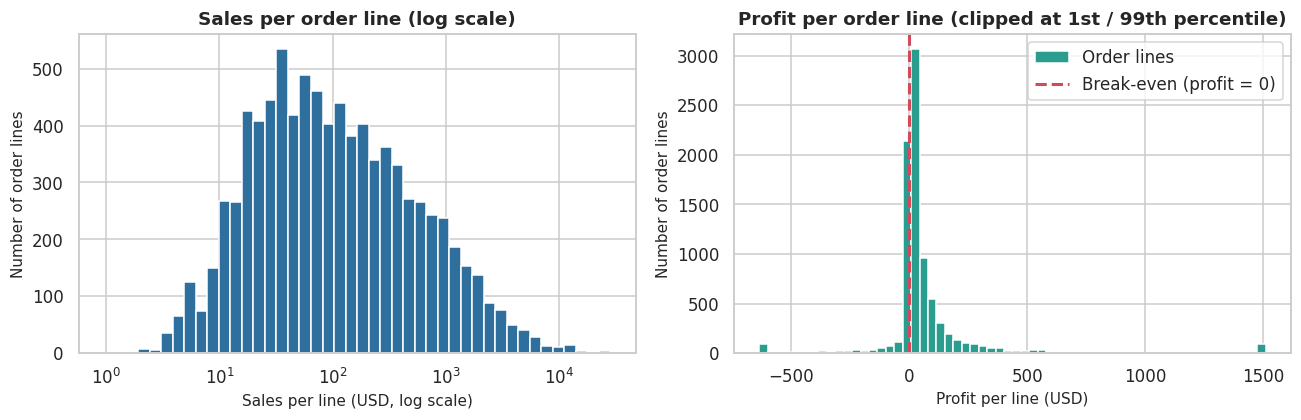

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
pos = sales_lines.sales[sales_lines.sales > 0]
ax[0].hist(pos, bins=np.logspace(np.log10(pos.min()), np.log10(pos.max()), 45), color=BLUE, edgecolor="white")
ax[0].set_xscale("log"); ax[0].set_title("Sales per order line (log scale)")
ax[0].set_xlabel("Sales per line (USD, log scale)"); ax[0].set_ylabel("Number of order lines")
lo, hi = sales_lines.profit.quantile([.01, .99])
ax[1].hist(sales_lines.profit.clip(lo, hi), bins=60, color=TEAL, edgecolor="white", label="Order lines")
ax[1].axvline(0, color=RED, ls="--", lw=2, label="Break-even (profit = 0)")
ax[1].set_title("Profit per order line (clipped at 1st / 99th percentile)")
ax[1].set_xlabel("Profit per line (USD)"); ax[1].set_ylabel("Number of order lines"); ax[1].legend()
plt.tight_layout(); save("01_distributions.png")
loss_line_share = (sales_lines.profit < 0).mean()
loss_line_n = int((sales_lines.profit < 0).sum())
loss_line_total = sales_lines.loc[sales_lines.profit < 0, "profit"].sum()
neg_loss = -loss_line_total
print(f"Loss-making sales lines: {loss_line_n:,} ({loss_line_share:.1%} of lines) losing USD {-loss_line_total:,.0f} in total")

**What this shows.** Line sales span several orders of magnitude, which is why the left chart needs a log axis. In the right chart most lines earn a small positive profit,
but there is a visible left tail: 1,138 lines (13.1%) lose money, together USD 214,571. Those loss lines are investigated in sections 5 and 8.

## 4. Monthly and seasonal sales trends

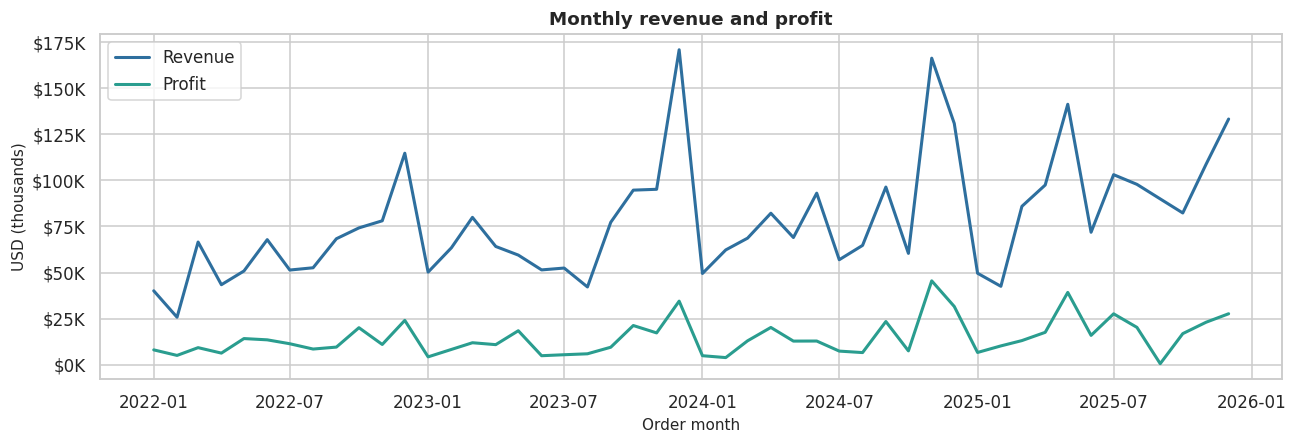

In [6]:
monthly = df.groupby(df.order_date.dt.to_period("M")).agg(revenue=("sales", "sum"), profit=("profit", "sum"))
monthly.index = monthly.index.to_timestamp()
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(monthly.index, monthly.revenue, color=BLUE, lw=2, label="Revenue")
ax.plot(monthly.index, monthly.profit, color=TEAL, lw=2, label="Profit")
ax.yaxis.set_major_formatter(usd_k); ax.set_title("Monthly revenue and profit")
ax.set_xlabel("Order month"); ax.set_ylabel("USD (thousands)"); ax.legend(loc="upper left")
plt.tight_layout(); save("02_monthly_trend.png")

              revenue    profit  orders  margin_pct  revenue_growth_pct
order_date                                                             
2022         733611.0  140676.0     768        19.0                 NaN
2023         901076.0  152306.0     931        17.0                23.0
2024        1000098.0  189378.0    1036        19.0                11.0
2025        1103748.0  218423.0    1160        20.0                10.0

Revenue share of the thin-margin sub-categories (Bookcases, Machines, Tables) by year, %:
order_date
2022    27.1
2023    32.2
2024    25.8
2025    26.4

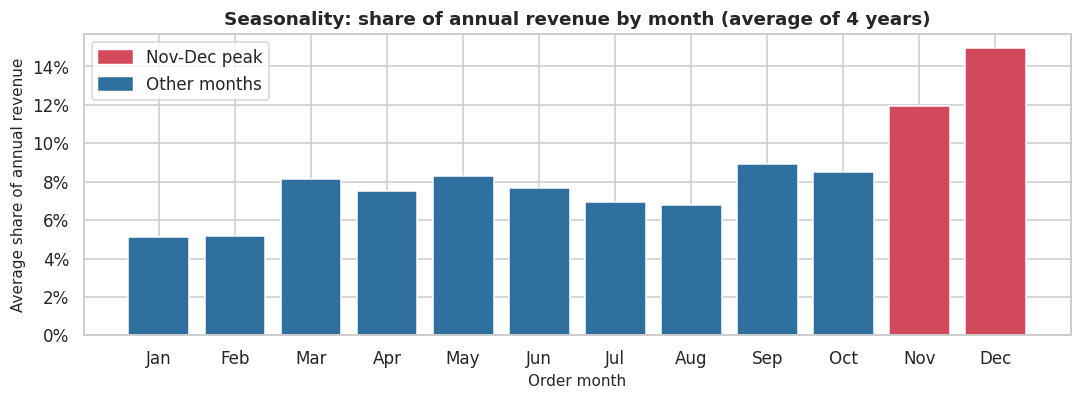

In [7]:
yearly = df.groupby(df.order_date.dt.year).agg(revenue=("sales", "sum"), profit=("profit", "sum"), orders=("order_id", "nunique"))
yearly["margin_pct"] = (yearly.profit / yearly.revenue * 100).round(1)
yearly["revenue_growth_pct"] = (yearly.revenue.pct_change() * 100).round(1)
print(yearly.round(0).to_string())

by_ym = df.groupby([df.order_date.dt.year.rename("year"), df.order_date.dt.month.rename("month")]).sales.sum().unstack()
avg_share = by_ym.div(by_ym.sum(axis=1), axis=0).mean() * 100          # average % of a year's revenue falling in each month
nov_dec, q4, jan_feb = avg_share[[11, 12]].sum(), avg_share[[10, 11, 12]].sum(), avg_share[[1, 2]].sum()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(range(1, 13), avg_share, color=[RED if m in (11, 12) else BLUE for m in range(1, 13)])
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.set_ylabel("Average share of annual revenue")
ax.set_xlabel("Order month"); ax.set_title("Seasonality: share of annual revenue by month (average of 4 years)")
ax.legend(handles=[Patch(color=RED, label="Nov-Dec peak"), Patch(color=BLUE, label="Other months")])
plt.tight_layout(); save("03_seasonality.png")

g23, g24, g25 = yearly.revenue_growth_pct.iloc[1:].tolist()
assert min(g23, g24, g25) > 0, "commentary says revenue grew every year"
margin_low_year, margin_low = int(yearly.margin_pct.idxmin()), yearly.margin_pct.min()
margin_first = yearly.margin_pct.iloc[0]
s = df.groupby("sub_category")[["sales", "profit"]].sum(); sub_margin = s.profit / s.sales * 100
weak_subs = sub_margin[sub_margin < 5].index.tolist()
weak_list = ", ".join(sorted(weak_subs))
weak_share = df[df.sub_category.isin(weak_subs)].groupby(df.order_date.dt.year).sales.sum() / yearly.revenue * 100
weak_share_peak_year, weak_share_peak = int(weak_share.idxmax()), weak_share.max()
weak_share_first = weak_share.iloc[0]
assert margin_low_year == weak_share_peak_year, "commentary below assumes the lowest-margin year is also the year of peak weak-category mix"
print("\nRevenue share of the thin-margin sub-categories (" + weak_list + ") by year, %:"); print(weak_share.round(1).to_string())

**What this shows.** Revenue grew every year: +22.8% in 2023, +11.0% in 2024 and +10.4% in 2025. The monthly chart is clearly seasonal. On average **November and December together
bring 26.9% of a year's revenue** (Q4: 35.4%), against only 10.3% in January and February combined, so inventory, staffing and promotion budgets should be planned around Q4.

Profit did not grow in step with revenue: the margin was lowest in 2023 (16.9% against 19.2% in the first year). That is also the year in which the thin-margin
sub-categories (Bookcases, Machines, Tables) had their largest share of revenue (32.2% versus 27.1% in the first year). **This is consistent with a product-mix effect, but it does not prove it**:
other things (discount depth, regional mix) also changed. Sections 5 to 8 test those explanations one at a time.

## 5. Category and sub-category analysis

                   revenue    profit  margin_pct  share_of_profit_pct
category                                                             
Furniture        1172045.0   62041.0         5.0                  9.0
Office Supplies   580181.0  173103.0        30.0                 25.0
Technology       1986307.0  465639.0        23.0                 66.0

       category sub_category  revenue   profit  margin  loss_line_pct
      Furniture       Tables 323396.4 -46422.6   -14.4           62.0
      Furniture    Bookcases 311642.6 -23216.2    -7.4           51.4
     Technology     Machines 402679.8   -782.9    -0.2           43.5
Office Supplies    Fasteners   5572.9   1766.1    31.7            3.0
Office Supplies       Labels   7690.1   3452.2    44.9            3.0
Office Supplies     Supplies  53700.2   5075.2     9.5           24.4
Office Supplies    Envelopes  15317.6   6353.4    41.5            1.4
Office Supplies      Binders  59496.2  13006.4    21.9           25.3
Office Supplies    

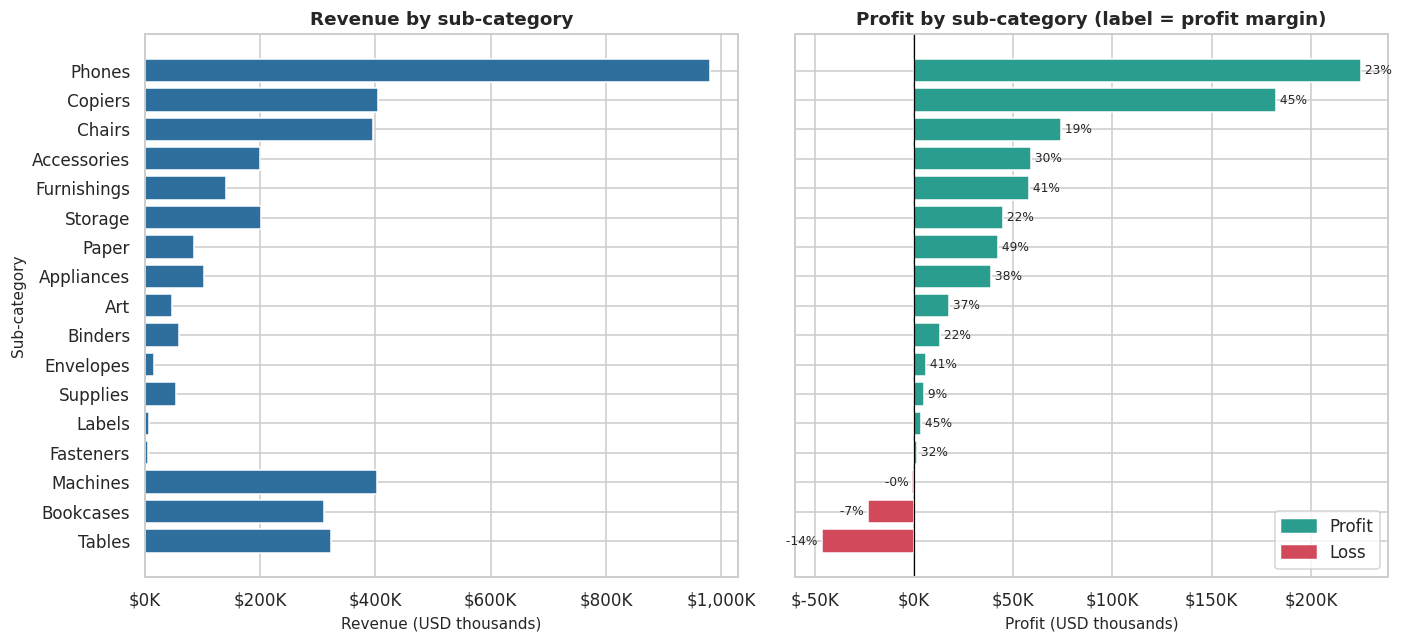

In [8]:
sub = df.groupby(["category", "sub_category"]).agg(revenue=("sales", "sum"), profit=("profit", "sum")).reset_index()
sub["margin"] = sub.profit / sub.revenue * 100
sub["loss_line_pct"] = sub.sub_category.map(sales_lines.groupby("sub_category").profit.apply(lambda x: (x < 0).mean() * 100))
sub = sub.sort_values("profit").reset_index(drop=True)

fig, ax = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
ax[0].barh(sub.sub_category, sub.revenue, color=BLUE); ax[0].xaxis.set_major_formatter(usd_k)
ax[0].set_title("Revenue by sub-category"); ax[0].set_xlabel("Revenue (USD thousands)"); ax[0].set_ylabel("Sub-category")
ax[1].barh(sub.sub_category, sub.profit, color=[RED if v < 0 else TEAL for v in sub.profit]); ax[1].xaxis.set_major_formatter(usd_k)
ax[1].axvline(0, color="black", lw=.8)
for i, (p, m) in enumerate(zip(sub.profit, sub.margin)):
    ax[1].text(p, i, f" {m:.0f}% " if p >= 0 else f" {m:.0f}% ", va="center", ha="left" if p >= 0 else "right", fontsize=8)
ax[1].set_title("Profit by sub-category (label = profit margin)"); ax[1].set_xlabel("Profit (USD thousands)")
ax[1].legend(handles=[Patch(color=TEAL, label="Profit"), Patch(color=RED, label="Loss")], loc="lower right")
plt.tight_layout(); save("04_subcategory.png")

cat = df.groupby("category").agg(revenue=("sales", "sum"), profit=("profit", "sum"))
cat["margin_pct"] = (cat.profit / cat.revenue * 100).round(1); cat["share_of_profit_pct"] = (cat.profit / cat.profit.sum() * 100).round(1)
print(cat.round(0).to_string()); print()
print(sub[["category", "sub_category", "revenue", "profit", "margin", "loss_line_pct"]].round(1).to_string(index=False))

loss_sub = sub[sub.profit < 0]
loss_sub_names = ", ".join(loss_sub.sort_values("profit").sub_category)
loss_sub_total, loss_sub_rev_share = -loss_sub.profit.sum(), loss_sub.revenue.sum() / revenue * 100
n_loss_sub = len(loss_sub)
best_cat = cat.margin_pct.idxmax(); best_cat_margin = cat.margin_pct.max()
tech_share = cat.loc["Technology", "share_of_profit_pct"]; tech_rev_share = cat.loc["Technology", "revenue"] / revenue * 100
worst_sub = sub.iloc[0]
worst_sub_name, worst_sub_margin, worst_sub_loss_pct = worst_sub.sub_category, worst_sub.margin, worst_sub.loss_line_pct

**What this shows.** 3 sub-categories lose money overall: **Tables, Bookcases, Machines**. Together they bring in 27.8% of revenue yet destroy USD 70,422 of profit.
The worst is Tables, with a margin of -14.4% and 62% of its sales lines individually unprofitable.
At the other end, Technology produces 66.4% of all profit from 53.1% of revenue. The category with the best margin is Office Supplies (29.8%).

Note the difference between *revenue* and *profit* rankings: the high-revenue sub-categories are not automatically the profitable ones. A report that ranks by revenue alone would point management at the wrong places.

## 6. Geographic performance

           revenue    profit  margin  rev_share  profit_share  pct_lines_discounted
region                                                                             
West     1051305.5  215990.2    20.5       28.1          30.8                  31.3
South    1003127.8  211171.7    21.1       26.8          30.1                  39.6
East      957777.2  189405.5    19.8       25.6          27.0                  35.3
Central   726322.7   84215.7    11.6       19.4          12.0                  52.9

Furniture margin in Central: -1.2%  vs other regions: 7.0%

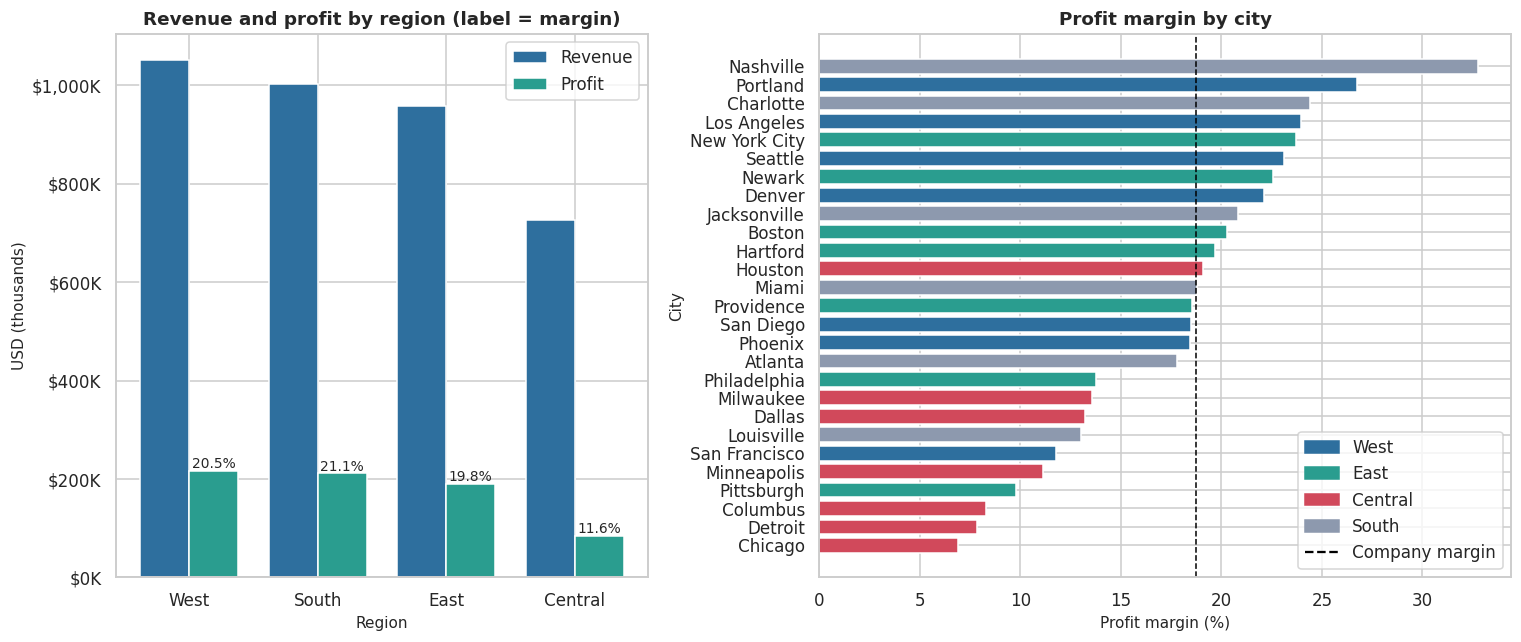

In [9]:
reg = df.groupby("region").agg(revenue=("sales", "sum"), profit=("profit", "sum"))
reg["margin"] = reg.profit / reg.revenue * 100
reg["rev_share"], reg["profit_share"] = reg.revenue / reg.revenue.sum() * 100, reg.profit / reg.profit.sum() * 100
reg["pct_lines_discounted"] = sales_lines.groupby("region").discount.apply(lambda x: (x > 0).mean() * 100)
reg = reg.sort_values("revenue", ascending=False)
city = df.groupby(["city", "region"]).agg(revenue=("sales", "sum"), profit=("profit", "sum")).reset_index()
city["margin"] = city.profit / city.revenue * 100; city = city.sort_values("margin")
REG_COL = {"West": BLUE, "East": TEAL, "Central": RED, "South": GREY}

fig, ax = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1.3]})
x = np.arange(len(reg)); w = .38
ax[0].bar(x - w / 2, reg.revenue, w, color=BLUE, label="Revenue"); ax[0].bar(x + w / 2, reg.profit, w, color=TEAL, label="Profit")
for i, m in enumerate(reg.margin): ax[0].text(i + w / 2, reg.profit.iloc[i], f"{m:.1f}%", ha="center", va="bottom", fontsize=9)
ax[0].set_xticks(x); ax[0].set_xticklabels(reg.index); ax[0].yaxis.set_major_formatter(usd_k)
ax[0].set_title("Revenue and profit by region (label = margin)"); ax[0].set_xlabel("Region"); ax[0].set_ylabel("USD (thousands)"); ax[0].legend()
ax[1].barh(city.city, city.margin, color=[REG_COL[r] for r in city.region]); ax[1].axvline(margin * 100, color="black", ls="--", lw=1)
ax[1].set_title("Profit margin by city"); ax[1].set_xlabel("Profit margin (%)"); ax[1].set_ylabel("City")
ax[1].legend(handles=[Patch(color=c, label=r) for r, c in REG_COL.items()] + [plt.Line2D([0], [0], color="black", ls="--", label="Company margin")], loc="lower right")
plt.tight_layout(); save("05_geography.png")

print(reg.round(1).to_string()); print()
worst_reg = reg.margin.idxmin(); worst_reg_margin = reg.margin.min()
rest = df[df.region != worst_reg]; rest_margin = rest.profit.sum() / rest.sales.sum() * 100
worst_disc_rate = reg.loc[worst_reg, "pct_lines_discounted"]
rest_disc_rate = (sales_lines[sales_lines.region != worst_reg].discount > 0).mean() * 100
worst_rev_share, worst_profit_share = reg.loc[worst_reg, "rev_share"], reg.loc[worst_reg, "profit_share"]
top_rev_region, top_rev_share = reg.revenue.idxmax(), reg.rev_share.max()
n_worst_in_bottom5 = int((city.head(5).region == worst_reg).sum())
fz = df[df.category == "Furniture"]
furn_worst = fz[fz.region == worst_reg]; furn_rest = fz[fz.region != worst_reg]
furn_worst_margin, furn_rest_margin = furn_worst.profit.sum() / furn_worst.sales.sum() * 100, furn_rest.profit.sum() / furn_rest.sales.sum() * 100
print(f"Furniture margin in {worst_reg}: {furn_worst_margin:.1f}%  vs other regions: {furn_rest_margin:.1f}%")

**What this shows.** West is the largest region by revenue (28.1%). The weakest is **Central**: it brings 19.4% of revenue but only 12.0% of profit,
at a margin of 11.6% compared with 20.5% for the other regions combined. 4 of the 5 lowest-margin cities are in Central.
A candidate explanation visible in the data is discounting: 53% of Central sales lines carry a discount against 35% elsewhere.
Furniture illustrates the effect: its margin is -1.2% in Central versus 7.0% in the other regions.

Region-level averages hide a lot (cities in the same region differ widely in the right-hand chart), which is why the Power BI report has city drill-down.

## 7. Product profitability

TOP 10 BY PROFIT
          product_name sub_category  revenue   profit  margin
     Stark Copier D252      Copiers 256036.8 118559.6    46.3
      Hooli Phone G269       Phones 305093.7  85533.6    28.0
     Globex Phone L274       Phones 135864.3  29557.4    21.8
      Stark Phone K273       Phones 141159.5  25564.9    18.1
   Vandelay Phone E267       Phones 151505.9  24891.7    16.4
     Stark Copier A249      Copiers  56074.2  24649.2    44.0
Contoso Accessory E239  Accessories  68839.7  20927.6    30.4
     Stark Copier C251      Copiers  43678.0  18461.0    42.3
Contoso Appliance A141   Appliances  43522.5  17271.7    39.7
   Vandelay Phone H270       Phones  53124.0  16214.0    30.5

BOTTOM 10 BY PROFIT
         product_name sub_category  revenue   profit  margin
     Stark Table H140       Tables  97820.0 -14271.0   -14.6
Tailspin Machine F260     Machines  84061.6 -12523.2   -14.9
      Acme Table B134       Tables  69880.2 -12288.6   -17.6
 Northwind Table D136       Tables  

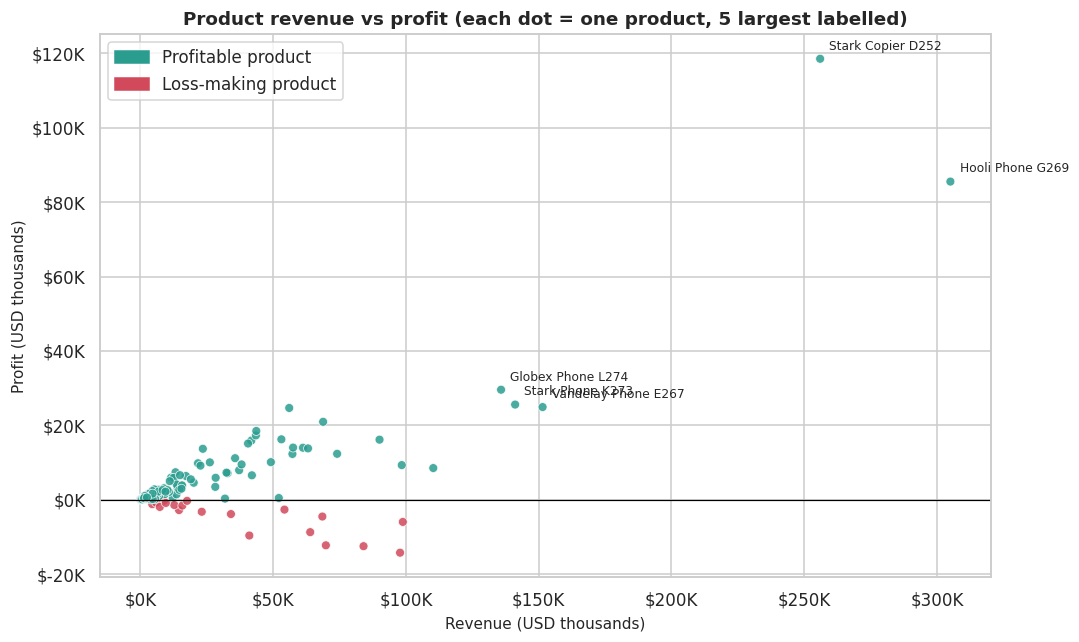

In [10]:
prod = df.groupby(["product_id", "product_name", "sub_category"]).agg(revenue=("sales", "sum"), profit=("profit", "sum")).reset_index()
prod["margin"] = prod.profit / prod.revenue * 100
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(prod.revenue, prod.profit, s=34, c=np.where(prod.profit < 0, RED, TEAL), alpha=.85, edgecolor="white", lw=.5)
ax.axhline(0, color="black", lw=.8)
for r in prod.nlargest(5, "revenue").itertuples():
    ax.annotate(r.product_name, (r.revenue, r.profit), xytext=(6, 6), textcoords="offset points", fontsize=8)
ax.xaxis.set_major_formatter(usd_k); ax.yaxis.set_major_formatter(usd_k)
ax.set_title("Product revenue vs profit (each dot = one product, 5 largest labelled)")
ax.set_xlabel("Revenue (USD thousands)"); ax.set_ylabel("Profit (USD thousands)")
ax.legend(handles=[Patch(color=TEAL, label="Profitable product"), Patch(color=RED, label="Loss-making product")], loc="upper left")
plt.tight_layout(); save("06_product_scatter.png")

cols = ["product_name", "sub_category", "revenue", "profit", "margin"]
print("TOP 10 BY PROFIT"); print(prod.nlargest(10, "profit")[cols].round(1).to_string(index=False))
print("\nBOTTOM 10 BY PROFIT"); print(prod.nsmallest(10, "profit")[cols].round(1).to_string(index=False))

loss_prod = prod[prod.profit < 0]; n_loss_prod, loss_prod_total = len(loss_prod), -loss_prod.profit.sum()
top10_profit_share = prod.nlargest(10, "profit").profit.sum() / profit * 100
srt = prod.sort_values("revenue", ascending=False); n_half = int((srt.revenue.cumsum() / srt.revenue.sum() <= .5).sum() + 1)
q75 = prod.revenue.quantile(.75)
hs = prod[(prod.revenue >= q75) & (prod.margin < 10)].sort_values("revenue", ascending=False)
n_top_quartile = int((prod.revenue >= q75).sum()); hs_rev_share, hs_profit = hs.revenue.sum() / revenue * 100, hs.profit.sum()
print(f"\nHIGH SALES (top revenue quartile, >= USD {q75:,.0f}) BUT MARGIN < 10%: {len(hs)} of {n_top_quartile} products"); print(hs[cols].round(1).to_string(index=False))
n_hs = len(hs)
assert set(hs.sub_category) <= set(loss_sub.sub_category), "commentary says all high-sales/low-margin products sit in the loss-making sub-categories"
top_name, top_rev = prod.nlargest(1, "revenue").iloc[0].product_name, prod.revenue.max()
best_profit_name, best_profit = prod.nlargest(1, "profit").iloc[0].product_name, prod.profit.max()

**What this shows.** Both revenue and profit are concentrated in few products: the 10 most profitable products produce 54.5% of total profit, and 16 of 174 products are enough to reach half of revenue.
The most profitable product is Stark Copier D252 (USD 118,560). **19 products lose money** (USD 89,307 combined).

The most useful finding for management is the *high sales, weak profit* group: of the 44 products in the top revenue quartile, **14 earn a margin below 10%**. They account for 24.8% of company revenue
but a combined profit of USD -59,391. Revenue rankings make these look like stars, while profit shows they are not. All of them belong to the sub-categories identified in section 5.

## 8. Discount and profit relationship

        lines    revenue    profit  loss_pct  margin
band                                                
0%       5255  2407890.2  773354.4       0.0    32.1
1-10%     533   249922.0   50268.7       1.5    20.1
11-20%   1452   679525.2   72590.9       9.9    10.7
21-30%    445   157518.0   -4403.9      29.7    -2.8
31-50%    565   161428.3  -67586.7      77.0   -41.9
>50%      419    82463.3 -123402.2     100.0  -149.6

Spearman correlation, discount vs line margin: -0.73 | Pearson: -0.83
Loss-making share by exact discount level:
          lines  loss_pct
discount                 
0.00       5255       0.0
0.10        533       1.5
0.15        422       4.7
0.20       1030      12.0
0.30        445      29.7
0.40        326      62.9
0.50        239      96.2
0.60        145     100.0
0.70        170     100.0
0.80        104     100.0

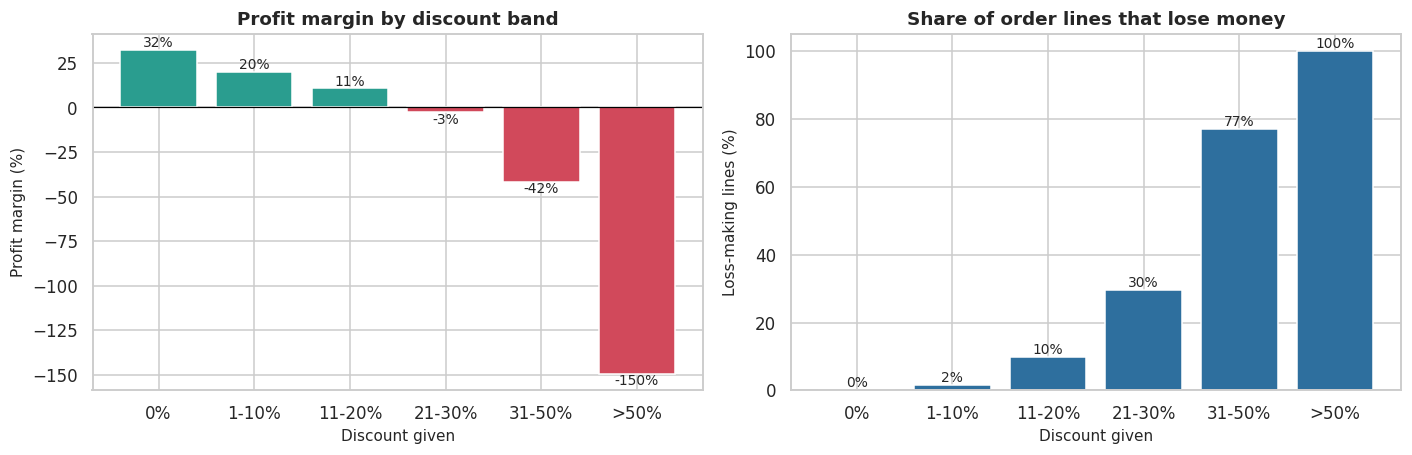

In [11]:
LABELS = ["0%", "1-10%", "11-20%", "21-30%", "31-50%", ">50%"]
sl = sales_lines.assign(band=pd.cut(sales_lines.discount, [-1, 0, .10, .20, .30, .50, 1], labels=LABELS))
bs = sl.groupby("band", observed=True).agg(lines=("sales", "size"), revenue=("sales", "sum"), profit=("profit", "sum"),
                                           loss_pct=("profit", lambda x: (x < 0).mean() * 100))
bs["margin"] = bs.profit / bs.revenue * 100
print(bs.round(1).to_string()); print()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ax[0].bar(bs.index.astype(str), bs.margin, color=[RED if v < 0 else TEAL for v in bs.margin]); ax[0].axhline(0, color="black", lw=.8)
for i, v in enumerate(bs.margin): ax[0].text(i, v, f"{v:.0f}%", ha="center", va="bottom" if v >= 0 else "top", fontsize=9)
ax[0].set_title("Profit margin by discount band"); ax[0].set_xlabel("Discount given"); ax[0].set_ylabel("Profit margin (%)")
ax[1].bar(bs.index.astype(str), bs.loss_pct, color=BLUE)
for i, v in enumerate(bs.loss_pct): ax[1].text(i, v, f"{v:.0f}%", ha="center", va="bottom", fontsize=9)
ax[1].set_title("Share of order lines that lose money"); ax[1].set_xlabel("Discount given"); ax[1].set_ylabel("Loss-making lines (%)")
plt.tight_layout(); save("07_discount_bands.png")

m_0, m_10, m_20, m_30, m_50, m_hi = bs.margin.tolist()
l_0, l_10, l_20, l_30, l_50, l_hi = bs.loss_pct.tolist()
neg_band = str(bs.index[bs.margin < 0][0])
corr_p, corr_s = sales_lines.discount.corr(sales_lines.profit_margin), sales_lines.discount.corr(sales_lines.profit_margin, method="spearman")
lvl = sales_lines.groupby("discount").agg(lines=("sales", "size"), loss_pct=("profit", lambda x: (x < 0).mean() * 100))
first_majority = lvl.index[lvl.loss_pct > 50].min()
profit_nodisc, profit_disc = sales_lines.loc[sales_lines.discount == 0, "profit"].sum(), sales_lines.loc[sales_lines.discount > 0, "profit"].sum()
share_lines_disc = (sales_lines.discount > 0).mean() * 100
share_rev_disc = sales_lines.loc[sales_lines.discount > 0, "sales"].sum() / sales_lines.sales.sum() * 100
hi = sales_lines[sales_lines.discount > .30]; hi_n, hi_share, hi_profit = len(hi), len(hi) / len(sales_lines) * 100, hi.profit.sum()
neg_hi_profit = -hi_profit
neg_profit_disc = -profit_disc
assert profit_disc < 0, "commentary says discounted lines lose money in total"
print(f"Spearman correlation, discount vs line margin: {corr_s:.2f} | Pearson: {corr_p:.2f}")
print(f"Loss-making share by exact discount level:"); print(lvl.round(1).to_string())

**What this shows.** Margin falls steadily as the discount deepens: 32.1% with no discount, 20.1% at up to 10%, 10.7% at 11-20%, then negative from the **21-30%** band
(-2.8%, -41.9% and -149.6% in the three deepest bands). The share of lines that lose money rises from 0% (no discount) to 10% (11-20%), 30% (21-30%), 77% (31-50%) and 100% above 50%.
Looking at exact discount levels, the first level at which most lines lose money is **40%**. The Spearman correlation between discount and line margin is -0.73.

39.4% of lines are discounted (35.6% of revenue), yet the discounted lines in total *lost* USD 72,533, while undiscounted lines earned USD 773,354:
**discounting as a whole subtracts profit in this dataset.** The 984 lines discounted by more than 30% (11.4% of lines) lost USD 190,989 on their own.

Largest loss-making sub-category x discount combinations (>= 15 lines):
sub_category   band  lines  revenue   profit  margin
   Bookcases 21-40%     59  52774.2 -14107.1   -26.7
      Tables 21-40%     71  45131.4 -15475.8   -34.3
      Phones 21-40%     37  44897.9  -1293.9    -2.9
   Bookcases   >40%     64  36414.5 -38637.9  -106.1
    Machines   >40%     26  35395.6 -40822.8  -115.3
      Tables   >40%     96  33942.5 -51300.0  -151.1

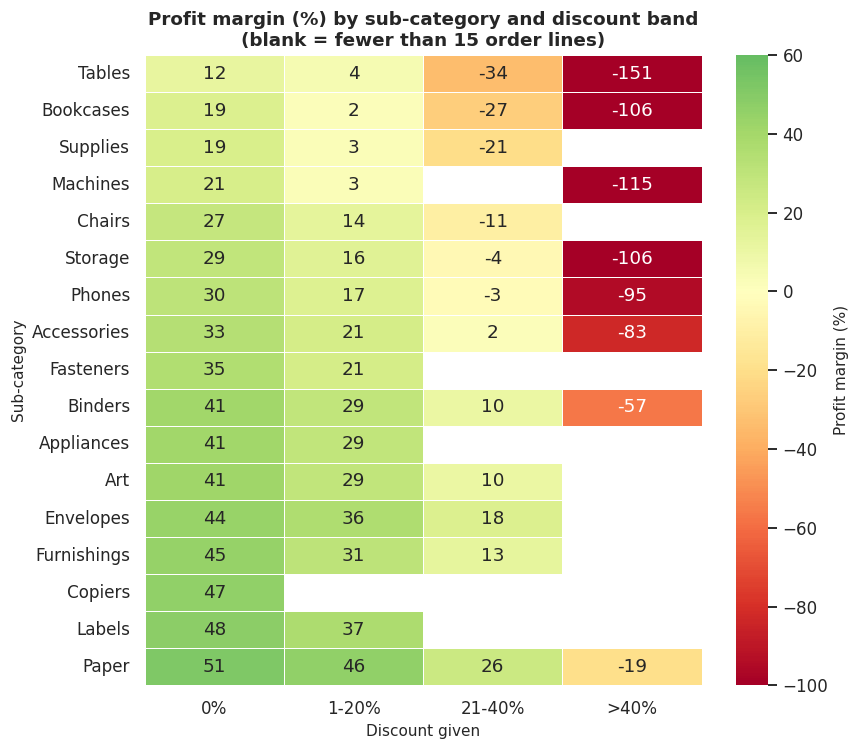

In [12]:
COARSE = ["0%", "1-20%", "21-40%", ">40%"]
c = sales_lines.assign(band=pd.cut(sales_lines.discount, [-1, 0, .20, .40, 1], labels=COARSE))
g = c.groupby(["sub_category", "band"], observed=True).agg(revenue=("sales", "sum"), profit=("profit", "sum"), lines=("sales", "size")).reset_index()
g["margin"] = g.profit / g.revenue * 100
heat = g.pivot(index="sub_category", columns="band", values="margin")[COARSE]
nlines = g.pivot(index="sub_category", columns="band", values="lines")[COARSE]
heat = heat.loc[heat["0%"].sort_values().index]
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(heat, mask=(nlines.loc[heat.index] < 15), annot=True, fmt=".0f", cmap="RdYlGn", center=0, vmin=-100, vmax=60,
            cbar_kws={"label": "Profit margin (%)"}, ax=ax, linewidths=.5)
ax.set_title("Profit margin (%) by sub-category and discount band\n(blank = fewer than 15 order lines)")
ax.set_xlabel("Discount given"); ax.set_ylabel("Sub-category"); ax.grid(False)
plt.tight_layout(); save("08_discount_heatmap.png")

combo = g[(g.margin < 0) & (g.lines >= 15)].sort_values("revenue", ascending=False)
print("Largest loss-making sub-category x discount combinations (>= 15 lines):")
print(combo.head(6)[["sub_category", "band", "lines", "revenue", "profit", "margin"]].round(1).to_string(index=False))
top_combo = f"{combo.iloc[0].sub_category} at {combo.iloc[0].band} discount"; top_combo_rev, top_combo_profit = combo.iloc[0].revenue, combo.iloc[0].profit
n_combo, combo_loss = len(combo), -combo.profit.sum()
undisc_loss_subs = heat.index[heat["0%"] < 15].tolist()
undisc_txt = ", ".join(sorted(undisc_loss_subs))
heat_ok = heat.where(nlines.loc[heat.index] >= 15)   # same 15-line threshold as the chart
both = heat_ok[[">40%", "0%"]].dropna(); n_cmp = len(both); n_dec = int((both[">40%"] < both["0%"]).sum())
assert n_dec >= 0.8 * n_cmp, "commentary assumes the deepest discount band has a lower margin in most sub-categories"

**What this shows.** The heatmap compares margins *within* each sub-category, so the pattern cannot be explained by product mix alone: in 8 of the 8 sub-categories that have enough lines in both bands, the over-40% band has a lower margin than the no-discount band.
There are 14 sub-category and discount-band combinations with a negative margin (at least 15 lines each), losing USD 188,292 in total. The largest by revenue is **Bookcases at 21-40% discount**
(USD 52,774 revenue, USD -14,107 profit). Some sub-categories (Tables) earn thin margins even at full price, so for them there is little room to discount at all.

### Correlation is not causation (read before acting on this)
* **What the data supports:** deeper discounts go together with lower margins (8 of 8 sub-categories compared), and the relationship is strong (Spearman -0.73).
* **What it does not prove:** that *removing* discounts would raise profit by the same amount. The dataset has no sales-volume counterfactual, so we cannot see how many extra units discounts generated, or whether those customers would have bought anyway.
* **Possible confounders:** discounts are not handed out at random. They are concentrated in particular products and, here, in particular regions, so product, region and customer effects are tangled together. Stratifying by sub-category (above) removes one of those, not all.
* **Mechanism and data limits:** the file has no cost field, so we cannot decompose profit into price and cost effects. In this synthetic dataset unit costs are fixed by construction, so a deeper discount mechanically cuts the margin. In real data one should check that costs did not move too.
* **How to find out for real:** run a controlled price test (for example, limit the discount in half the comparable orders) and compare profit *and* volume.

## 9. Customer segment comparison

             customers  orders    revenue    profit  margin  avg_order_value  rev_share  pct_lines_discounted
segment                                                                                                      
Consumer           403    2106  1987599.0  359663.3    18.1            943.8       53.2                  39.3
Corporate          221    1099  1113046.1  226676.3    20.4           1012.8       29.8                  39.4
Home Office        130     690   637888.0  114443.6    17.9            924.5       17.1                  39.4

Orders per year by segment:
segment  Consumer  Corporate  Home Office
year                                     
2022          422        210          136
2023          471        284          176
2024          586        272          178
2025          627        333          200
Consumer     margin 18.1%   95% bootstrap interval 16.1% to 20.3%
Corporate    margin 20.4%   95% bootstrap interval 17.0% to 24.0%
Home Office  margin 17.9%   95% boots

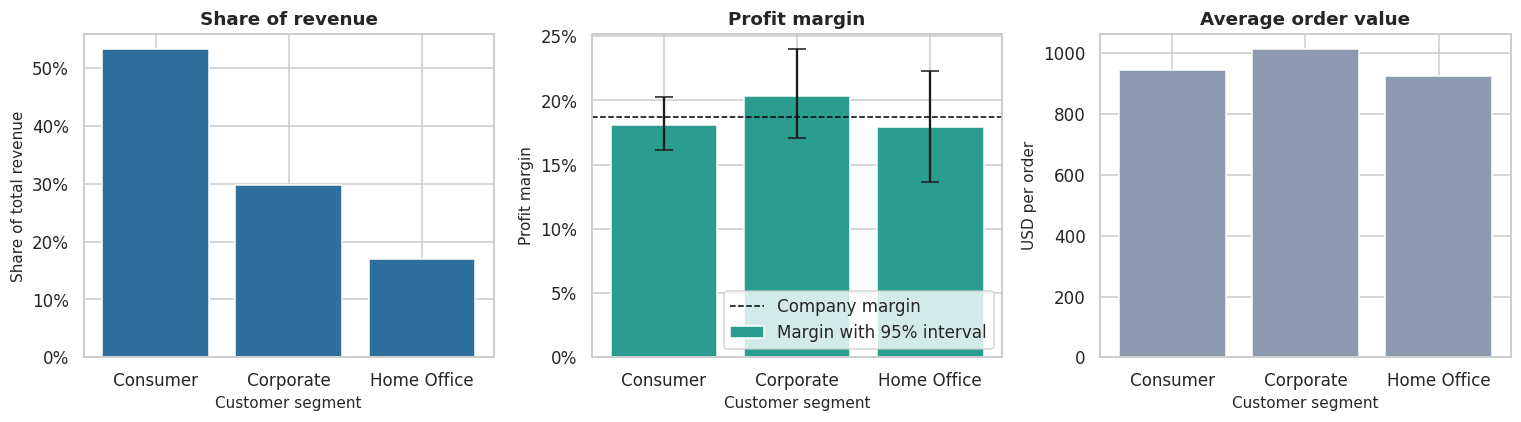

In [13]:
seg = df.groupby("segment").agg(customers=("customer_id", "nunique"), orders=("order_id", "nunique"), revenue=("sales", "sum"), profit=("profit", "sum"))
seg["margin"] = seg.profit / seg.revenue * 100
seg["avg_order_value"], seg["rev_share"] = seg.revenue / seg.orders, seg.revenue / seg.revenue.sum() * 100
seg["pct_lines_discounted"] = sales_lines.groupby("segment").discount.apply(lambda x: (x > 0).mean() * 100)
seg = seg.sort_values("revenue", ascending=False)
print(seg.round(1).to_string()); print()
print("Orders per year by segment:"); print(df.groupby([df.order_date.dt.year.rename("year"), "segment"]).order_id.nunique().unstack().to_string())

# How much of the margin gap could be random noise? Bootstrap: resample order lines 1,000 times per segment.
rng = np.random.default_rng(0); ci = {}
for name, d in df.groupby("segment"):
    s_, p_ = d.sales.to_numpy(), d.profit.to_numpy()
    idx = rng.integers(0, len(d), (1000, len(d)))
    ci[name] = np.percentile(p_[idx].sum(axis=1) / s_[idx].sum(axis=1) * 100, [2.5, 97.5])
    print(f"{name:12s} margin {seg.loc[name, 'margin']:.1f}%   95% bootstrap interval {ci[name][0]:.1f}% to {ci[name][1]:.1f}%")
names = list(seg.index)
sep = [(a, b) for i, a in enumerate(names) for b in names[i + 1:] if ci[a][0] > ci[b][1] or ci[b][0] > ci[a][1]]
seg_conclusion = ("The 95% intervals overlap for every pair of segments, so these data do not show a reliable difference in profitability between segments."
                  if not sep else "Intervals do not overlap for: " + "; ".join(f"{a} vs {b}" for a, b in sep) + ".")

seg_conclusion_short = "95% intervals overlap for every pair" if not sep else "some pairs differ beyond chance"

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].bar(seg.index, seg.rev_share, color=BLUE); ax[0].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax[0].set_title("Share of revenue"); ax[0].set_xlabel("Customer segment"); ax[0].set_ylabel("Share of total revenue")
err = np.array([[seg.loc[n, "margin"] - ci[n][0], ci[n][1] - seg.loc[n, "margin"]] for n in seg.index]).T
ax[1].bar(seg.index, seg.margin, yerr=err, capsize=6, color=TEAL, label="Margin with 95% interval"); ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax[1].axhline(margin * 100, color="black", ls="--", lw=1, label="Company margin"); ax[1].legend(loc="lower right")
ax[1].set_title("Profit margin"); ax[1].set_xlabel("Customer segment"); ax[1].set_ylabel("Profit margin")
ax[2].bar(seg.index, seg.avg_order_value, color=GREY); ax[2].set_title("Average order value"); ax[2].set_xlabel("Customer segment"); ax[2].set_ylabel("USD per order")
plt.tight_layout(); save("09_segments.png")
top_seg, top_seg_share = seg.rev_share.idxmax(), seg.rev_share.max()
corp_aov_seg, corp_aov = seg.avg_order_value.idxmax(), seg.avg_order_value.max()
seg_margin_min, seg_margin_max = seg.margin.min(), seg.margin.max()
disc_min, disc_max = seg.pct_lines_discounted.min(), seg.pct_lines_discounted.max()

Top 10% of customers = 38.6% of revenue | repeat customers (2+ orders) = 82.5% of customers, 97.0% of revenue

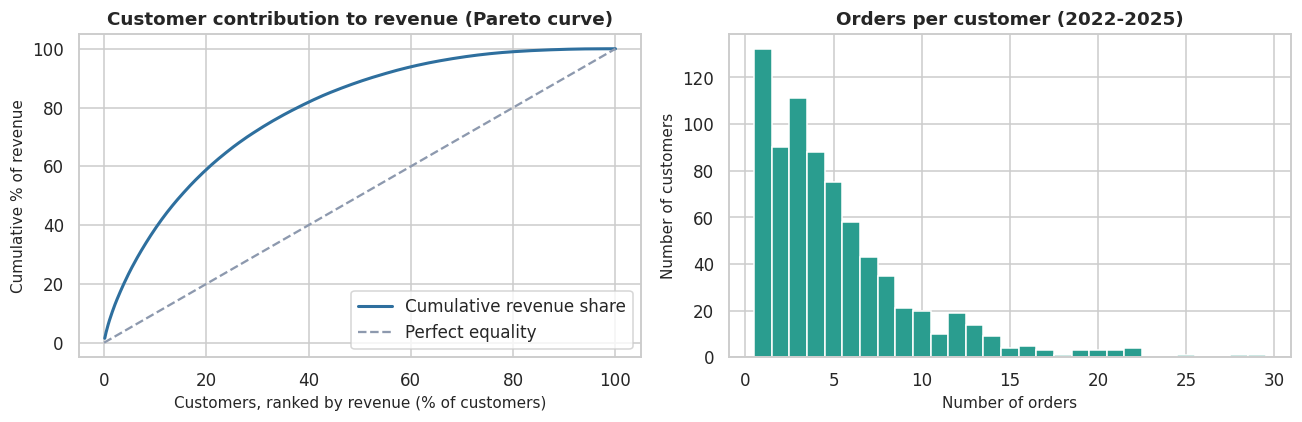

In [14]:
cust = df.groupby("customer_id").agg(revenue=("sales", "sum"), orders=("order_id", "nunique")).sort_values("revenue", ascending=False)
cum = cust.revenue.cumsum() / cust.revenue.sum() * 100
top10_cust_share = cum.iloc[int(len(cust) * .10) - 1]
rep = cust.orders >= 2
repeat_cust_pct, repeat_rev_share = rep.mean() * 100, cust.loc[rep, "revenue"].sum() / cust.revenue.sum() * 100
heavy = cust.orders >= 5; heavy_cust_pct, heavy_rev_share = heavy.mean() * 100, cust.loc[heavy, "revenue"].sum() / cust.revenue.sum() * 100
one_time_n, avg_orders = int((~rep).sum()), cust.orders.mean()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(np.arange(1, len(cust) + 1) / len(cust) * 100, cum, color=BLUE, lw=2, label="Cumulative revenue share")
ax[0].plot([0, 100], [0, 100], color=GREY, ls="--", label="Perfect equality")
ax[0].set_title("Customer contribution to revenue (Pareto curve)"); ax[0].set_xlabel("Customers, ranked by revenue (% of customers)")
ax[0].set_ylabel("Cumulative % of revenue"); ax[0].legend(loc="lower right")
ax[1].hist(cust.orders, bins=np.arange(.5, cust.orders.max() + 1.5, 1), color=TEAL, edgecolor="white")
ax[1].set_title("Orders per customer (2022-2025)"); ax[1].set_xlabel("Number of orders"); ax[1].set_ylabel("Number of customers")
plt.tight_layout(); save("10_customers.png")
print(f"Top 10% of customers = {top10_cust_share:.1f}% of revenue | repeat customers (2+ orders) = {repeat_cust_pct:.1f}% of customers, {repeat_rev_share:.1f}% of revenue")

**What this shows.** Consumer is the largest segment (53.2% of revenue). Corporate has the highest average order value (USD 1,013).
Segment margins sit between 17.9% and 20.4%, and the share of discounted lines is almost identical across segments (39.3% to 39.4%).
The 95% intervals overlap for every pair of segments, so these data do not show a reliable difference in profitability between segments. **Do not read a story into small gaps**: the error bars show how much a margin can move by chance alone.

Customer value is concentrated in loyal buyers. The top 10% of customers bring 38.6% of revenue, and customers with 5 or more orders are 44.2% of customers but 74.4% of revenue.
Repeat customers (2+ orders) are 82.5% of customers and 97.0% of revenue; 132 customers bought only once.
Caveat: the data start in 2022, so a customer who bought once in 2025 may simply be new, not lost. A proper retention analysis would need a cohort view.

## 10. Outlier investigation

Flagged lines:
 row_id       order_id             product_name  quantity  discount   sales   profit
    108 US-2022-100050    Vandelay Art Set H158         2      0.00   374.8   369.36
    537 US-2022-100229 Vandelay Paper Ream H208         1      0.15  1120.4  1103.15
   1579 US-2022-100715         Stark Table H140         2      0.15 11720.4 11385.80
   2306 US-2023-101040    Stark Furnishing E123         3      0.00  8007.2  7888.76
   3489 US-2023-101559 Vandelay Paper Ream C203         2      0.00  1935.6  1912.52
   6108 US-2024-102733      Acme Accessory L246         1      0.00   684.0   673.57

KPIs with vs without the 6 flagged lines -> revenue 3,738,533 vs 3,714,691 | profit 700,783 vs 677,450 | margin 18.74% vs 18.24%

3xIQR screen: 152 large lines, of which 4 are the flagged price outliers; median quantity of the rest = 8 (all lines: 3)

Five largest loss lines:
 row_id          product_name  quantity  discount   sales   profit
   2985 Tailspin Machine F260         7      

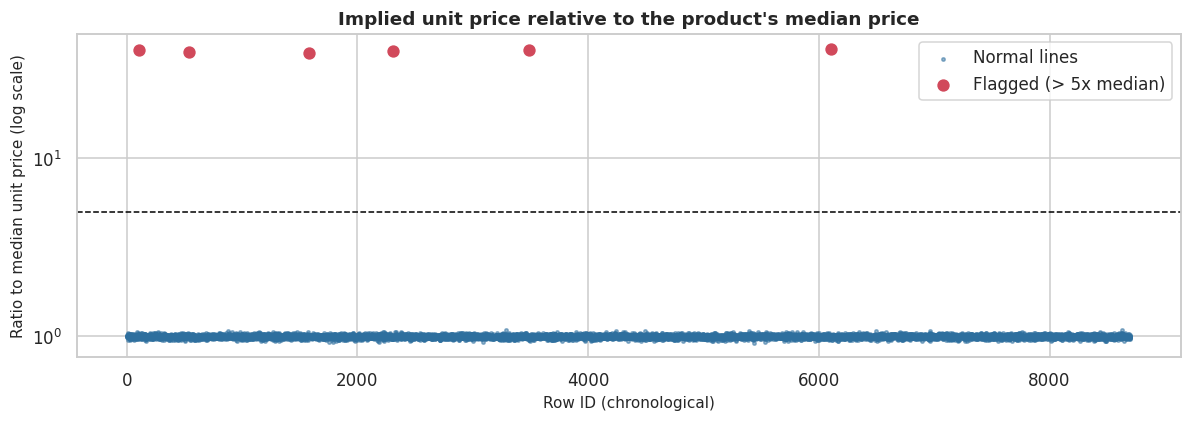

In [15]:
margin_pct = margin * 100
nr = sales_lines.copy()
nr["unit_list"] = nr.sales / (nr.quantity * (1 - nr.discount))          # implied list price per unit, undoing the discount
nr["ratio"] = nr.unit_list / nr.groupby("product_id").unit_list.transform("median")
flagged = df[df.is_price_outlier == 1]
fig, ax = plt.subplots(figsize=(11, 4))
ok = nr[nr.is_price_outlier == 0]; bad = nr[nr.is_price_outlier == 1]
ax.scatter(ok.row_id, ok.ratio, s=5, color=BLUE, alpha=.5, label="Normal lines")
ax.scatter(bad.row_id, bad.ratio, s=50, color=RED, label="Flagged (> 5x median)")
ax.axhline(5, color="black", ls="--", lw=1); ax.set_yscale("log")
ax.set_title("Implied unit price relative to the product's median price"); ax.set_xlabel("Row ID (chronological)"); ax.set_ylabel("Ratio to median unit price (log scale)"); ax.legend()
plt.tight_layout(); save("11_price_outliers.png")

print("Flagged lines:"); print(flagged[["row_id", "order_id", "product_name", "quantity", "discount", "sales", "profit"]].to_string(index=False))
n_flag = len(flagged); flag_sales, flag_profit = flagged.sales.sum(), flagged.profit.sum()
flag_sales_pct, flag_profit_pct = flag_sales / revenue * 100, flag_profit / profit * 100
margin_ex = (profit - flag_profit) / (revenue - flag_sales) * 100
print(f"\nKPIs with vs without the {n_flag} flagged lines -> revenue {revenue:,.0f} vs {revenue - flag_sales:,.0f} | profit {profit:,.0f} vs {profit - flag_profit:,.0f} | margin {margin * 100:.2f}% vs {margin_ex:.2f}%")

# A second, independent screen: large sales within a sub-category (3 x IQR rule). Large is not the same as wrong.
q1 = sales_lines.groupby("sub_category").sales.transform(lambda x: x.quantile(.25)); q3 = sales_lines.groupby("sub_category").sales.transform(lambda x: x.quantile(.75))
iqr_out = sales_lines[sales_lines.sales > q3 + 3 * (q3 - q1)]
n_iqr, n_iqr_flagged = len(iqr_out), int(iqr_out.is_price_outlier.sum())
med_qty_iqr, med_qty_all = iqr_out[iqr_out.is_price_outlier == 0].quantity.median(), sales_lines.quantity.median()
print(f"\n3xIQR screen: {n_iqr} large lines, of which {n_iqr_flagged} are the flagged price outliers; median quantity of the rest = {med_qty_iqr:.0f} (all lines: {med_qty_all:.0f})")

worst = sales_lines.nsmallest(20, "profit")
worst_disc = worst.discount.mean() * 100; worst_total = -worst.profit.sum()
print("\nFive largest loss lines:"); print(worst.head(5)[["row_id", "product_name", "quantity", "discount", "sales", "profit"]].to_string(index=False))

**What this shows.** Two different kinds of unusual values appear, and they need different treatment.

1. **Suspected keying errors (6 lines).** Their implied unit price is 5x or more above the product's own median, far outside normal variation. They are *kept but flagged*, because a data analyst cannot be sure they are wrong.
   Their effect is small on revenue (0.6% of total) but larger on profit (3.3%), because an inflated sale price has almost no matching cost. Excluding them changes the margin from 18.74% to 18.24%.
   In Power BI this is a one-click slicer on `is_price_outlier`.
2. **Large but plausible lines (152 lines on the 3xIQR screen).** Beyond the 4 flagged ones, the remaining large lines are mostly driven by higher quantity (median quantity 8 against 3 overall), which is a legitimate bulk order, not an error.

The most negative profit lines are not errors either: the 20 worst lines average a 64% discount and lose USD 49,408 together, which links back to section 8. **Rule of thumb used here: delete only what is provably invalid, flag what is merely unusual, and keep real losses.**

## 11. Reconciliation with the SQL layer
The same KPIs were computed in SQL (`sql/business_analysis.sql`, run on the star schema). They must match this notebook exactly.

In [16]:
res = Path("../reports/sql_results")
if (res / "q_Q01_total_revenue_profit.csv").exists():
    k1 = pd.read_csv(res / "q_Q01_total_revenue_profit.csv").iloc[0]; k2 = pd.read_csv(res / "q_Q02_orders_and_units.csv").iloc[0]
    pairs = {"Revenue": (k1.total_revenue, revenue), "Profit": (k1.total_profit, profit), "Orders": (k2.total_orders, n_orders), "Units": (k2.units_sold, units)}
    for k, (s_, p_) in pairs.items():
        print(f"{k:8s} SQL {s_:>14,.2f}   Python {p_:>14,.2f}   difference {abs(s_ - p_):.4f}")
        assert abs(s_ - p_) < 0.011, f"{k} does not reconcile"
    print("\nSQL and Python agree on all headline KPIs. The full 31-check reconciliation is in reports/reconciliation_report.md.")
else:
    print("Run `python src/sql_runner.py` first to create the SQL result files.")

Revenue  SQL   3,738,533.15   Python   3,738,533.15   difference 0.0000
Profit   SQL     700,783.13   Python     700,783.13   difference 0.0000
Orders   SQL       3,895.00   Python       3,895.00   difference 0.0000
Units    SQL      33,100.00   Python      33,100.00   difference 0.0000

SQL and Python agree on all headline KPIs. The full 31-check reconciliation is in reports/reconciliation_report.md.

## 12. Summary of findings
All figures below were computed in this notebook.

| # | Finding | Evidence |
|---|---|---|
| 1 | Revenue USD 3,738,533, profit USD 700,783, margin 18.7%, growing every year | section 2 and 4 |
| 2 | Q4 carries the year: Nov-Dec = 26.9% of annual revenue | section 4 |
| 3 | 3 sub-categories (Tables, Bookcases, Machines) are loss-making overall; together USD 70,422 lost on 27.8% of revenue | section 5 |
| 4 | Central has 19.4% of revenue but 12.0% of profit (margin 11.6% vs 20.5% elsewhere); 53% of its lines are discounted vs 35% elsewhere | section 6 |
| 5 | 14 of the 44 top-revenue-quartile products earn under 10% margin; 19 products lose money in total | section 7 |
| 6 | Margin is 32% undiscounted and -150% above 50% discount; lines discounted over 30% lost USD 190,989 | section 8 |
| 7 | Segment margins differ little (17.9% to 20.4%): 95% intervals overlap for every pair | section 9 |
| 8 | 6 suspected keying errors flagged; they are 0.6% of revenue but 3.3% of profit | section 10 |

**Limitations.** Synthetic data (no real business conclusions) · no cost or inventory fields · single country · no returns reasons · observational data, so discount effects are associations, not proven causes ·
customer "new vs returning" is censored at the start of the data window.